In [2]:
!pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 934.7 kB/s eta 0:06:16
   ---------------------------------------- 0.8/351.2 MB 1.1 MB/s eta 0:05:21
   ---------------------------------------- 1.0/351.2 MB 1.1 MB/s eta 0:05:11
   ---------------------------------------- 1.3/351.2 MB 1.2 MB/s eta 0:04:58
   ---------------------------------------- 1.6/351.2 MB 1.2 MB/s eta 0:04:42
   ---------------------------------------- 1.8/351.2 MB 1.3 MB/s eta 0:04:29
   ---------------------------------------- 2.4/351.2 MB 1.3 MB/s eta 0:04:22
   ---------------------------------------- 2.6/351.2 MB 1.4 MB/s eta 0:04:14
   ---------------------------------------- 3.1/351.2 MB 1.4 MB/s eta 0:04:03
   ---------------------------------------- 3.1/351.2 MB 1.4 MB/s eta 0:04:03
   --

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [9]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Opción 1: Apuntando directamente a la carpeta ya descomprimida en tu Escritorio
ruta_dataset = r"C:\Users\Pc\Desktop\dataset_animales"

print("Cargando generadores de datos...")
datagen_entrenamiento = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

datagen_val_prueba = ImageDataGenerator(rescale=1./255)

gen_entrenamiento = datagen_entrenamiento.flow_from_directory(
    f"{ruta_dataset}/entrenamiento",
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

gen_validacion = datagen_val_prueba.flow_from_directory(
    f"{ruta_dataset}/validacion",
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

print("\n¡Generadores cargados con éxito!")

Cargando generadores de datos...
Found 464 images belonging to 5 classes.
Found 83 images belonging to 5 classes.

¡Generadores cargados con éxito!


In [10]:
print("Construyendo la arquitectura MobileNetV2...")
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Congelamos la base

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)

num_clases = gen_entrenamiento.num_classes
salida = Dense(num_clases, activation='softmax')(x)

modelo = Model(inputs=base_model.input, outputs=salida)

modelo.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Iniciando entrenamiento...")
historial = modelo.fit(
    gen_entrenamiento,
    validation_data=gen_validacion,
    epochs=5
)

# Guardar el modelo
modelo.save("clasificador_animales_mobilenetv2.h5")
print("\n¡Modelo entrenado y guardado como 'clasificador_animales_mobilenetv2.h5'!")

Construyendo la arquitectura MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Iniciando entrenamiento...
Epoch 1/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.7672 - loss: 0.6457 - val_accuracy: 0.9759 - val_loss: 0.0927
Epoch 2/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 971ms/step - accuracy: 0.9289 - loss: 0.2205 - val_accuracy: 0.9880 - val_loss: 0.0579
Epoch 3/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 796ms/step - accuracy: 0.9698 - loss: 0.0986 - val_accuracy: 0.9880 - val_loss: 0.0212
Epoch 4/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 886ms/step - accuracy: 0.9634 - loss: 0.1136 - val_accuracy: 0.9759 - val_loss: 0.0505
Epoch 5/5
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 802ms/step - accuracy: 0.9784 - loss: 0.0827 - val_accuracy: 0.9880 - val_loss: 0.0324



¡Modelo entrenado y guardado como 'clasificador_animales_mobilenetv2.h5'!


In [12]:
def predecir_imagen(ruta_imagen):
    # Cargar y redimensionar la imagen
    img = image.load_img(ruta_imagen, target_size=(224, 224))
    
    # Convertir a arreglo y normalizar
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = x / 255.0
    
    # Predecir
    prediccion = modelo.predict(x)
    clases = list(gen_entrenamiento.class_indices.keys())
    
    # Mostrar imagen
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
    
    # Resultado
    indice_clase = np.argmax(prediccion[0])
    clase_predicha = clases[indice_clase]
    confianza = prediccion[0][indice_clase] * 100
    
    print(f"Predicción: {clase_predicha.upper()}")
    print(f"Confianza: {confianza:.2f}%")

print("¡Función de predicción lista para Jupyter!")

¡Función de predicción lista para Jupyter!


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


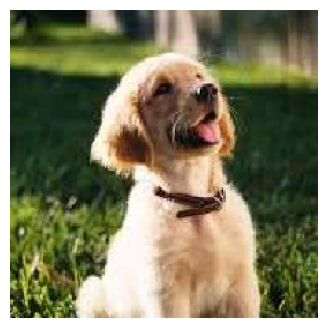

Predicción: DOG
Confianza: 100.00%


In [13]:
ruta_de_prueba = r"C:\Users\Pc\Desktop\descarga.jpg" 
predecir_imagen(ruta_de_prueba)